# Workshop 3: Segmentación de clientes con Clustering
**K-Means vs. Agglomerative vs. DBSCAN** — Mall Customer Segmentation Data

Pregunta de negocio: *¿En cuántos grupos "naturales" se dividen los clientes del centro comercial y qué caracteriza a cada uno?*

> En la versión del CSV que usamos la columna de género se llama `Gender` (el enunciado la llama `Genre`, el nombre de la versión original del dataset). El contenido es el mismo, así que en todo el notebook usamos `Gender` y `Gender_encoded`.

**Integrantes**

- Juan José Escobar Saldarriaga
- Jeremías Figueroa García 
- David Quintero Gallego

## Fase 0 — Carga y preprocesamiento

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")

# Dataset descargado de Kaggle y guardado localmente en la carpeta data/
path = "data"
df = pd.read_csv(f"{path}/Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Interpretación.** Cada fila es un cliente, con su identificador, género, edad, ingreso anual y Spending Score. Ya en estas primeras filas se ve que clientes con el mismo ingreso (15 k$) pueden tener puntajes de gasto muy distintos (39 vs 81), lo que anticipa que el ingreso por sí solo no explica el gasto.

In [2]:
print("Shape:", df.shape)
print("\nNulos por columna:\n", df.isnull().sum())
print("\nTipos de dato:\n", df.dtypes)
print("\nDuplicados:", df.duplicated().sum())
df.describe().round(2)

Shape: (200, 5)

Nulos por columna:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Tipos de dato:
 CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Duplicados: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


**Interpretación de la exploración.**

- 200 clientes, sin nulos ni duplicados: no hace falta imputar ni limpiar.
- **Edad:** de 18 a 70 años, con mediana de 36. La media (38.9) está por encima de la mediana, así que predominan los clientes jóvenes y hay una cola de clientes mayores.
- **Ingreso anual:** de 15 a 137 k$, con mediana de 61.5. El máximo está muy lejos del percentil 75 (78 k$): unos pocos clientes de ingreso muy alto estiran la distribución hacia la derecha.
- **Spending Score:** de 1 a 99, con media ≈ mediana ≈ 50. Es un puntaje construido por el centro comercial, por eso está centrado y es bastante simétrico.
- Las tres variables numéricas tienen escalas distintas (desviaciones de 14, 26 y 26), lo que ya anticipa la necesidad de estandarizar.

88 hombres y 112 mujeres en el dataset.


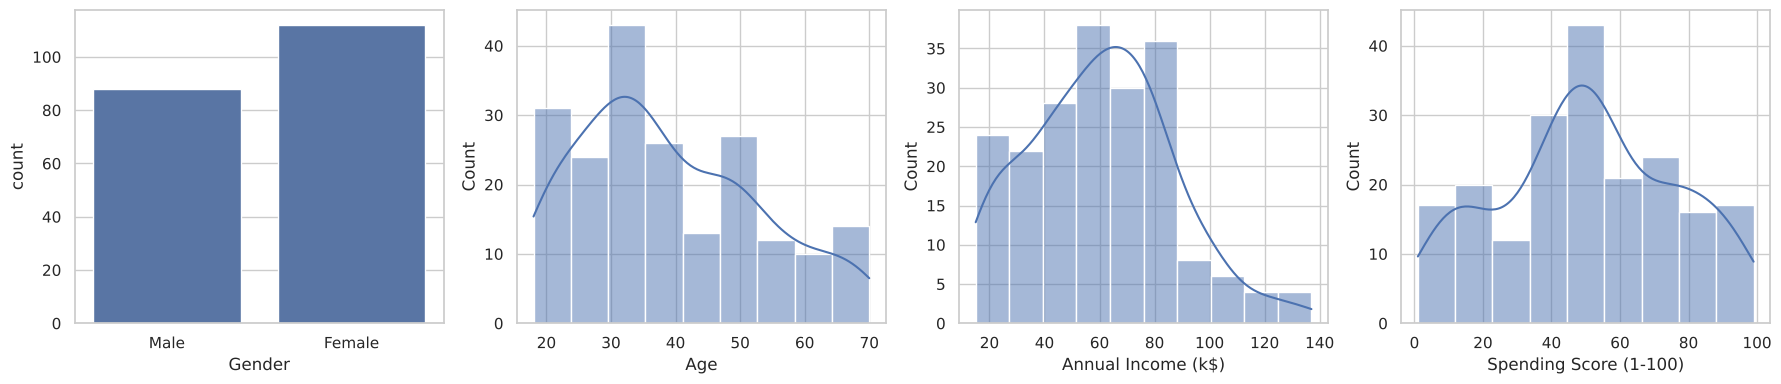

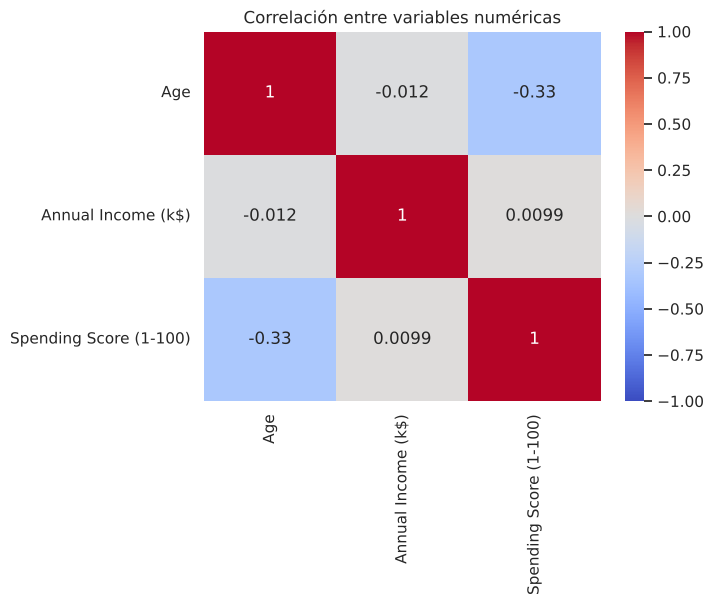

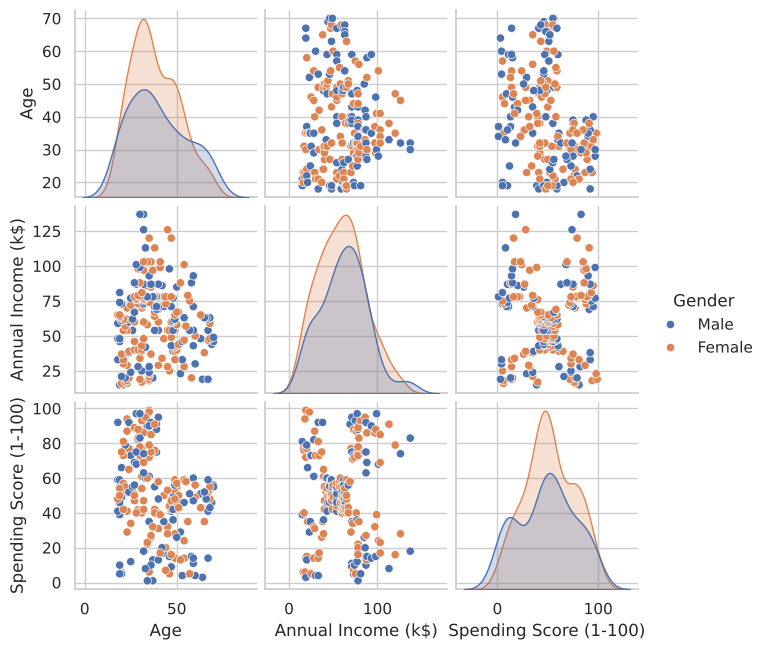

In [3]:
print(f"{df[df['Gender'] == 'Male'].shape[0]} hombres y {df[df['Gender'] == 'Female'].shape[0]} mujeres en el dataset.")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.countplot(data=df, x="Gender", ax=axes[0])
for ax, col in zip(axes[1:], ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    sns.histplot(df[col], kde=True, ax=ax)
plt.tight_layout(); plt.show()

sns.heatmap(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas"); plt.show()

sns.pairplot(df.drop(columns="CustomerID"), hue="Gender", height=2.2); plt.show()

In [4]:
# ¿El género cambia el comportamiento de compra por sí solo?
df.groupby("Gender")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)

,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.1,59.2,51.5
Male,39.8,62.2,48.5


**Interpretación de las gráficas.**

- **Género:** 112 mujeres (56 %) y 88 hombres (44 %). Hay algo más de mujeres, pero no es un desbalance grave.
- **Histogramas:** la edad se concentra entre los 20 y los 50 años; el ingreso tiene sesgo a la derecha; el Spending Score tiene una zona central (≈ 40–60) con más clientes y colas hacia ambos extremos.
- **Correlaciones:** todas son débiles. La única apreciable es *Age–Spending Score* (≈ −0.33): los clientes mayores tienden a gastar algo menos. El ingreso no se relaciona linealmente ni con la edad (≈ −0.01) ni con el gasto (≈ 0.01).
- Que las correlaciones sean bajas **no** significa que no haya estructura. En el pairplot, el panel *ingreso vs. spending score* muestra varios bloques separados (una zona central y cuatro "esquinas"), una relación no lineal que la correlación no captura. Es justo el tipo de estructura que el clustering puede encontrar.
- **Género:** en el pairplot los colores de hombres y mujeres se superponen en todos los paneles, y las medias por género son casi iguales (edad 38 vs 40, ingreso 59 vs 62, gasto 52 vs 49). El género, por sí solo, **no diferencia el comportamiento de compra**. Esto es clave para más adelante: si algún cluster se separa por género, no será porque haya un segmento de compra distinto.

**Preguntas**

- **¿Hay valores nulos?** No. Las 200 filas tienen las 5 columnas completas, y tampoco hay filas duplicadas.
- **¿Tipos de dato?** `CustomerID`, `Age`, `Annual Income (k$)` y `Spending Score (1-100)` son numéricas (enteros). `Gender` es la única categórica (texto con dos valores: Male/Female).

### 2.2 y 2.3 — Selección de variables y codificación de `Gender`

`CustomerID` se elimina porque es solo un identificador: si se incluyera, clientes con números de ID cercanos parecerían "similares" sin ninguna razón de negocio.

`Gender` tiene solo 2 categorías y no tiene un orden natural. Con 2 categorías, mapear a 0/1 equivale a un One-Hot con una sola columna (la segunda columna sería redundante, porque es exactamente la complementaria) y no impone ningún orden artificial, así que usamos `.map()`.

In [5]:
df = df.drop(columns="CustomerID", errors="ignore")
df["Gender_encoded"] = df["Gender"].map({"Male": 0, "Female": 1})
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded
0,Male,19,15,39,0
1,Male,21,15,81,0
2,Female,20,16,6,1
3,Female,23,16,77,1
4,Female,31,17,40,1


**Interpretación.** Quedan las 4 variables de la segmentación; `Gender_encoded` vale 1 para mujeres y 0 para hombres. La columna de texto `Gender` se conserva solo para describir los clusters en la Fase 7; no entra al clustering.

### 2.4 — Estandarización

In [6]:
features = ["Gender_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print(df[features].std().round(2))
print("\nDesviación estándar tras escalar:", X_scaled.std(axis=0).round(2))
print("Valores de Gender_encoded tras escalar:", np.unique(X_scaled[:, 0]).round(3))

Gender_encoded             0.50
Age                       13.97
Annual Income (k$)        26.26
Spending Score (1-100)    25.82
dtype: float64

Desviación estándar tras escalar: [1. 1. 1. 1.]
Valores de Gender_encoded tras escalar: [-1.128  0.886]


**¿Por qué estandarizar?** Los tres algoritmos se basan en distancias euclidianas. Sin escalar, la variable con mayor rango domina la distancia: `Annual Income` va de 15 a 137 (σ ≈ 26) y `Age` de 18 a 70 (σ ≈ 14), mientras que `Gender_encoded` solo vale 0/1 (σ = 0.5). El género casi no pesaría y el ingreso pesaría más que la edad solo por estar en otra unidad, no por ser más importante. `StandardScaler` transforma cada variable con

$$z = \frac{x - \mu}{\sigma}$$

de modo que todas quedan con media 0 y desviación 1 (como confirma la salida) y aportan de forma comparable. En DBSCAN además `eps` es una distancia fija, y solo tiene sentido si todas las variables están en la misma escala.

**Efecto secundario importante:** tras escalar, los hombres quedan en −1.13 y las mujeres en 0.89, es decir, a ≈ **2 unidades** de distancia en esa dimensión. Como referencia, la desviación estándar de las otras variables *dentro* de cada cluster está entre ≈ 0.3 y 0.7 unidades. El género pasa de casi no pesar a pesar mucho, y eso explica varios resultados de las fases siguientes (clusters formados por un solo género).

## Fase 1 — K-Means

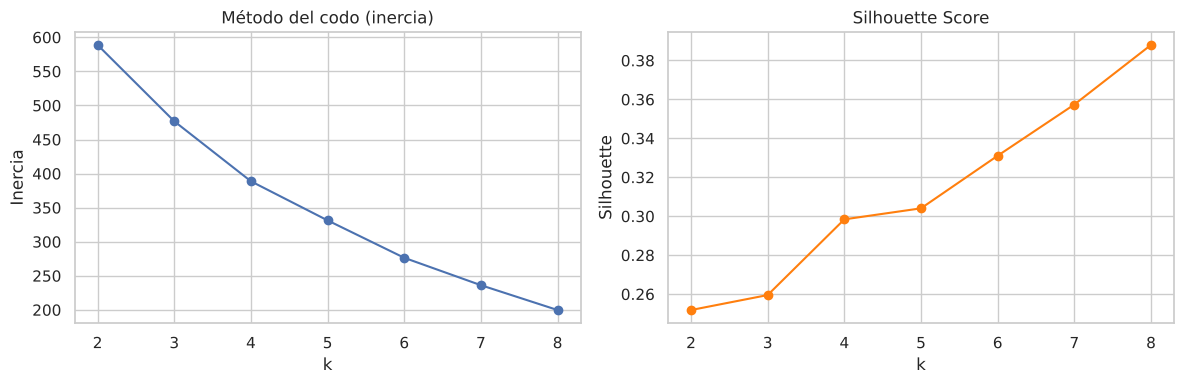

,k,Inercia,Silhouette Score,Caída de inercia
0,2,588.8,0.2518,NaN
1,3,476.8,0.2595,-112.0
2,4,388.7,0.2984,-88.1
3,5,331.3,0.3041,-57.4
4,6,276.4,0.3311,-54.9
5,7,236.2,0.3574,-40.2
6,8,199.8,0.3880,-36.4


In [7]:
ks = range(2, 9)
inertias, sil_km = [], []

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    sil_km.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Método del codo (inercia)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inercia")
axes[1].plot(list(ks), sil_km, "o-", color="tab:orange"); axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

tabla_km = pd.DataFrame({"k": list(ks), "Inercia": np.round(inertias, 1), "Silhouette Score": np.round(sil_km, 4)})
tabla_km["Caída de inercia"] = tabla_km["Inercia"].diff().round(1)
tabla_km

**Interpretación de las curvas y la tabla.**

- La **inercia** es la suma de distancias al cuadrado de cada punto a su centroide:

$$\text{Inercia} = \sum_{i=1}^{n} \left\lVert x_i - \mu_{c(i)} \right\rVert^2$$

Siempre baja al aumentar k (más centroides → cada punto queda más cerca del suyo), así que lo que importa es *cuánto* baja. Las caídas son 112 → 88 → 57 → 55 → 40 → 36. El cambio de pendiente más marcado ocurre al llegar a **k = 4** (la caída pasa de 88 a 57); después las caídas son parecidas entre sí. El codo no es nítido y está en la zona k = 4–5.

- El **Silhouette** mide, para cada punto, qué tan cerca está de su propio cluster comparado con el cluster vecino:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

donde $a(i)$ es la distancia media de $i$ a los puntos de su propio cluster y $b(i)$ la distancia media a los puntos del cluster más cercano. Va de −1 a 1. Aquí crece casi siempre con k (0.25 → 0.39) y todos los valores son modestos (< 0.4): los grupos se tocan en los bordes, no son bloques perfectamente aislados.
- k = 4 y k = 5 tienen un Silhouette casi igual (0.298 vs 0.304), así que la métrica no decide entre ellos.

**Preguntas**

1. **¿El codo coincide con el k de mayor Silhouette?** No. El codo está en k = 4–5, mientras que dentro del rango pedido el Silhouette es máximo en k = 8 (0.388). Las celdas siguientes muestran por qué el Silhouette sigue subiendo: a partir de cierto k los clusters se separan por género.
2. **k elegido para K-Means: k = 5.** El codo y el Silhouette no distinguen entre 4 y 5, así que lo desempatamos con tres criterios:
   - **k = 4 no separa por ingreso** (celda siguiente): sus 4 grupos son solo "jóvenes que gastan más / mayores que gastan menos" × "hombres / mujeres", todos con ingreso medio de ≈ 60 k$. Con k = 5 aparecen por primera vez los grupos de **alto ingreso** (alto gasto y bajo gasto), que son los más relevantes para el negocio.
   - **Desde k = 6**, los grupos nuevos aparecen al partir un grupo existente por género, no por comportamiento de compra.
   - Ward con k = 5 produce casi la misma partición (91 % de acuerdo, Fase 2).

In [8]:
# ¿Qué grupos produce K-Means con k = 4? (para compararlo con k = 5)
lab_k4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_scaled)
perfil_k4 = df.assign(Cluster_k4=lab_k4).groupby("Cluster_k4")[features].mean().round(1)
perfil_k4["n"] = np.bincount(lab_k4)
perfil_k4

,Gender_encoded,Age,Annual Income (k$),Spending Score (1-100),n
Cluster_k4,,,,,
0,1.0,47.8,58.1,34.9,56
1,0.0,28.0,62.2,64.8,46
2,1.0,28.4,60.4,68.2,56
3,0.0,52.7,62.2,30.6,42


**Interpretación.** Los 4 grupos tienen `Gender_encoded` de exactamente 0 o 1 (son de un solo género) y un ingreso medio casi idéntico (58–62 k$). Lo único que separan es edad + gasto (jóvenes con gasto ≈ 65–68 vs mayores con gasto ≈ 31–35), cruzado con el género. Con k = 4 el ingreso no participa en la segmentación, y se pierde el grupo de "alto ingreso y bajo gasto", que es el hallazgo de negocio más importante del análisis. Por eso preferimos k = 5.

In [9]:
# Exploración extendida: ¿por qué el Silhouette sigue subiendo con k?
# Para cada k contamos cuántos clusters quedan formados por un solo género.
filas = []
for k in range(2, 20):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    tabla = pd.crosstab(lab, df["Gender"])
    puros = int((tabla.min(axis=1) == 0).sum())
    filas.append((k, round(silhouette_score(X_scaled, lab), 4), puros, int(np.bincount(lab).min())))

tabla_ext = pd.DataFrame(filas, columns=["k", "Silhouette", "Clusters de un solo género", "Tamaño del cluster más pequeño"])
tabla_ext["% clusters de un solo género"] = (100 * tabla_ext["Clusters de un solo género"] / tabla_ext["k"]).round(0)
tabla_ext

,k,Silhouette,Clusters de un solo género,Tamaño del cluster más pequeño,% clusters de un solo género
0,2,0.2518,0,97,0.0
1,3,0.2595,2,49,67.0
2,4,0.2984,4,42,100.0
3,5,0.3041,2,29,40.0
4,6,0.3311,4,23,67.0
5,7,0.3574,6,18,86.0
6,8,0.3880,8,18,100.0
7,9,0.4031,9,13,100.0
8,10,0.4208,9,13,90.0
9,11,0.4275,11,8,100.0


**Interpretación.**

- Con k = 4 los 4 clusters son de un solo género (coherente con el perfil de la celda anterior) y con k = 5 solo 2 de 5. Desde **k = 8**, prácticamente **todos** los clusters son de un solo género (100 % en k = 8, 9 y desde k = 11; 9 de 10 en k = 10).
- El Silhouette forma una meseta (≈ 0.41–0.43) entre k = 10 y k = 17, con máximo en k = 14 (0.432). No hay un pico claro que señale un k "natural".
- La explicación es el escalado: hombres y mujeres quedan a ≈ 2 unidades de distancia, más que la dispersión típica dentro de un grupo. Separar por género produce clusters muy "limpios" y sube el Silhouette, aunque el comportamiento de compra de hombres y mujeres sea casi el mismo (Fase 0).
- Además, los clusters se vuelven pequeños: con k = 14 el menor tiene 5 clientes, muy poco para una campaña de marketing o para entrenar un clasificador.
- **Conclusión:** el Silhouette alto con k grande es un efecto de la variable binaria, no evidencia de más segmentos. Mantenemos k = 5.

## Fase 2 — Clustering jerárquico aglomerativo

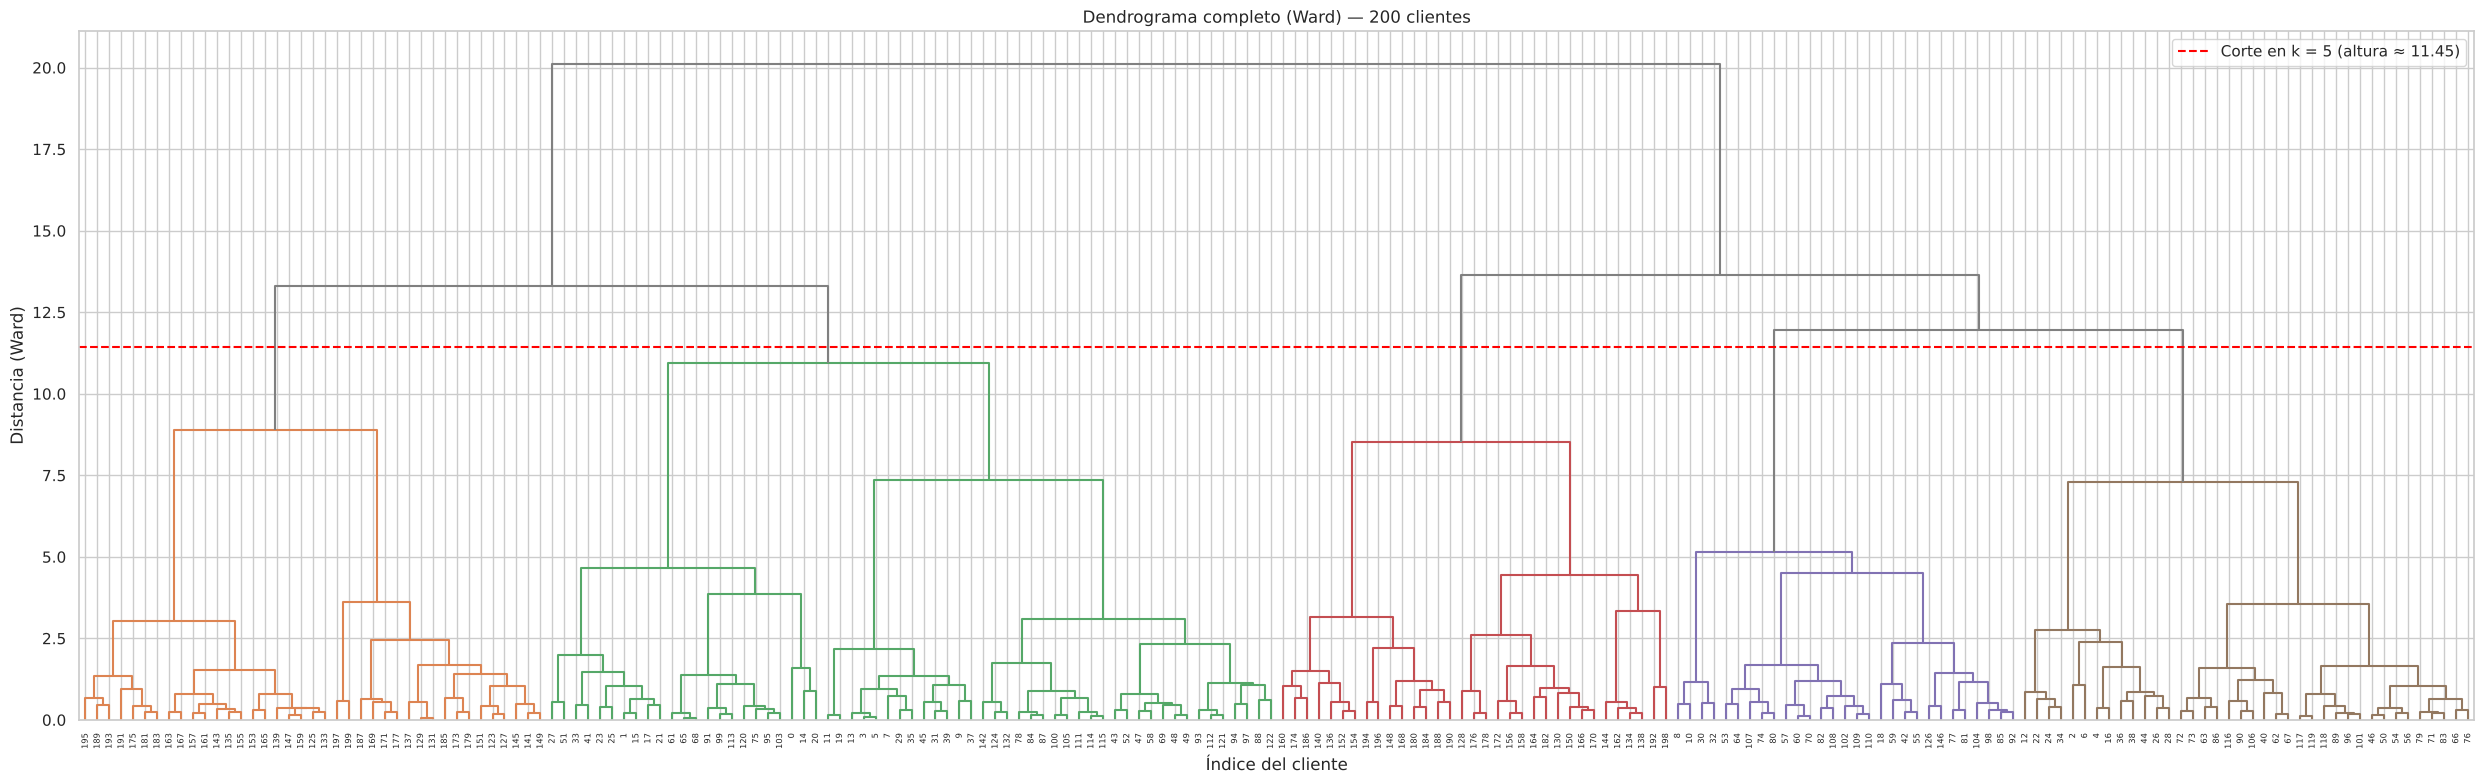

Tamaño de cada grupo al cortar: [39 61 33 29 38]
 k (grupos al cortar)  Fusión superior  Fusión inferior  Salto
                    2            20.12            13.64   6.47
                    3            13.64            13.31   0.33
                    4            13.31            11.96   1.35
                    5            11.96            10.93   1.03
                    6            10.93             8.88   2.05
                    7             8.88             8.51   0.37
                    8             8.51             7.37   1.14
                    9             7.37             7.28   0.09
                   10             7.28             5.15   2.14


In [10]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

Z = linkage(X_scaled, method="ward")

# Altura de corte para obtener k grupos: punto medio entre la fusión (k-1) y la k desde arriba
k_corte = 5
altura_corte = (Z[-(k_corte - 1), 2] + Z[-k_corte, 2]) / 2

plt.figure(figsize=(25, 8))
dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=6,
    color_threshold=altura_corte,     # colorea cada grupo por debajo del corte
    above_threshold_color="gray"
)
plt.axhline(altura_corte, color="red", linestyle="--",
            label=f"Corte en k = {k_corte} (altura ≈ {altura_corte:.2f})")
plt.title("Dendrograma completo (Ward) — 200 clientes")
plt.xlabel("Índice del cliente")
plt.ylabel("Distancia (Ward)")
plt.legend()
plt.tight_layout()
plt.show()

# Verificación: tamaños de los grupos que salen al cortar en esa altura
labels_corte = fcluster(Z, t=k_corte, criterion="maxclust")
print("Tamaño de cada grupo al cortar:", np.bincount(labels_corte)[1:])

# Saltos entre las últimas fusiones, indicando cuántos grupos quedan si se corta en cada hueco
dist = Z[-10:, 2][::-1]
tabla_saltos = pd.DataFrame({
    "k (grupos al cortar)": range(2, 11),
    "Fusión superior": dist[:-1].round(2),
    "Fusión inferior": dist[1:].round(2),
    "Salto": (dist[:-1] - dist[1:]).round(2)
})
print(tabla_saltos.to_string(index=False))

**Interpretación del dendrograma y de la tabla de saltos.**

- Cada hoja de la base es un cliente y cada unión horizontal es una fusión. La altura de la unión indica cuánto aumenta la varianza interna al juntar esos dos grupos (criterio de Ward): una fusión muy alta junta grupos muy distintos.
- Para leer cuántos grupos sugiere, se buscan los **huecos verticales grandes** entre fusiones consecutivas. Cortar dentro de un hueco grande separa grupos que el algoritmo tuvo que "forzar" para unir.
- El hueco más grande (6.47) corresponde a **k = 2**: los datos se dividen primero en dos ramas de 100 clientes cada una (ver la celda siguiente).
- El siguiente hueco claro (2.05) corresponde a **k = 6**, y después el de k = 10 (2.14), ya con grupos pequeños.
- El corte en **k = 5** cae en un hueco pequeño (1.03): el dendrograma lo admite, pero no lo destaca. Los grupos que produce tienen 39, 61, 33, 29 y 38 clientes, los mismos tamaños que `AgglomerativeClustering` con k = 5.

In [11]:
# ¿Qué separa a las dos grandes ramas del dendrograma?
from scipy.cluster.hierarchy import fcluster

ramas = fcluster(Z, t=2, criterion="maxclust")
perfil_ramas = df.assign(Rama=ramas).groupby("Rama")[features].mean().round(1)
perfil_ramas["n"] = np.bincount(ramas)[1:]
perfil_ramas

,Gender_encoded,Age,Annual Income (k$),Spending Score (1-100),n
Rama,,,,,
1,0.6,28.7,60.4,68.0,100
2,0.5,49.0,60.7,32.4,100


**Interpretación.** Las dos ramas no se separan por género (≈ 59 % y 53 % de mujeres) ni por ingreso (≈ 60 k$ en ambas), sino por **edad y gasto**: una rama agrupa a clientes jóvenes que gastan más (≈ 29 años, Spending Score ≈ 68) y la otra a clientes mayores que gastan menos (≈ 49 años, Spending Score ≈ 32). Es la misma relación *Age–Spending* (≈ −0.33) vista en las correlaciones, y es la diferencia más fuerte del dataset.

In [12]:
sil_ag = []
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    sil_ag.append(silhouette_score(X_scaled, lab))

tabla_ag = pd.DataFrame({"k": list(ks), "Silhouette Score": np.round(sil_ag, 4)})
tabla_ag

,k,Silhouette Score
0,2,0.2418
1,3,0.2483
2,4,0.2632
3,5,0.2870
4,6,0.3102
5,7,0.3456
6,8,0.3789


**Interpretación.** Igual que en K-Means, el Silhouette del aglomerativo crece con k. Para todos los valores de k es algo menor que el de K-Means (por ejemplo, 0.287 vs 0.304 con k = 5). Es esperable: K-Means reubica los puntos en cada iteración para que queden cerca de su centroide, mientras que Ward nunca deshace una fusión, así que algunos puntos de frontera quedan en un grupo que no es el más cercano.

**Preguntas**

- **¿Cuántos grupos sugiere el dendrograma?** El salto más grande indica 2 grupos (jóvenes que gastan más vs. mayores que gastan menos), demasiado grueso para segmentar clientes. El siguiente salto claro indica **6 grupos**. El corte en 5 cae en un hueco pequeño: el dendrograma lo admite, pero no lo señala como corte natural.
- **¿Coincide con el mejor k según Silhouette?** No. El Silhouette es máximo en k = 8 (0.379), por el mismo efecto del género visto en K-Means, mientras que el dendrograma sugiere 2 o 6. Usamos k = 5 para comparar con K-Means; la tabla cruzada siguiente muestra que ambos métodos llegan casi a los mismos grupos.

In [13]:
from sklearn.metrics import adjusted_rand_score

labels_km5 = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)
labels_ag5 = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(X_scaled)

print("Adjusted Rand Index (K-Means vs Agglomerative):", round(adjusted_rand_score(labels_km5, labels_ag5), 3))
pd.crosstab(labels_km5, labels_ag5, rownames=["K-Means"], colnames=["Agglomerative"])

Adjusted Rand Index (K-Means vs Agglomerative): 0.79


Agglomerative,0,1,2,3,4
K-Means,,,,,
0,0,39,0,0,0
1,3,0,26,0,0
2,5,0,2,36,0
3,52,0,0,2,0
4,1,0,5,0,29


**Interpretación de la tabla cruzada.** Las filas son los clusters de K-Means y las columnas los de Ward; cada celda cuenta los clientes con esa combinación. Los números de cluster de cada método son arbitrarios, así que cada cluster de K-Means se empareja con la columna donde tiene más clientes:

| K-Means | ≈ Ward | Clientes en común | % del cluster de K-Means |
|---:|---:|---:|---:|
| 0 (alto ingreso, alto gasto) | 1 | 39 de 39 | 100 % |
| 1 (alto ingreso, bajo gasto) | 2 | 26 de 29 | 90 % |
| 2 (mujeres, perfil medio) | 3 | 36 de 43 | 84 % |
| 3 (jóvenes, ingreso bajo) | 0 | 52 de 54 | 96 % |
| 4 (hombres, perfil medio) | 4 | 29 de 35 | 83 % |

- En total, **182 de 200 clientes (91 %)** reciben el mismo grupo en ambos métodos. El *Adjusted Rand Index* de 0.79 (1 = particiones idénticas, ≈ 0 = coincidencia al azar) lo confirma sin depender de la numeración.
- El grupo de alto ingreso y alto gasto coincide al 100 %: es el más separado de todos.
- Las diferencias están en las fronteras: Ward agranda su cluster 0 (61 clientes vs 54) con clientes que K-Means asigna a otros grupos, y los dos grupos de perfil medio (clusters 2 y 4 de K-Means) son los que más se reparten.
- Que dos algoritmos con lógicas distintas lleguen casi a los mismos grupos indica que la estructura de 5 grupos es estable y no un artefacto de un método.

## Fase 3 — DBSCAN

In [14]:
rows = []
for eps in [0.3, 0.5, 0.7, 0.9, 1.1]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        mask = lab != -1
        sil = silhouette_score(X_scaled[mask], lab[mask]) if n_cl > 1 else np.nan
        rows.append((eps, ms, n_cl, n_noise, round(sil, 4) if not np.isnan(sil) else np.nan))

grid = pd.DataFrame(rows, columns=["eps", "min_samples", "n_clusters", "n_ruido", "silhouette (sin ruido)"])
grid

,eps,min_samples,n_clusters,n_ruido,silhouette (sin ruido)
0,0.3,3,14,144,0.6293
1,0.3,5,1,194,NaN
2,0.3,8,0,200,NaN
3,0.3,10,0,200,NaN
4,0.5,3,18,49,0.4746
5,0.5,5,9,105,0.5395
6,0.5,8,2,169,0.7089
7,0.5,10,2,178,0.7694
8,0.7,3,9,14,0.1322
9,0.7,5,7,37,0.2766


**Interpretación de la exploración de parámetros.**

- Hay tres regiones. Con `eps` pequeño (0.3) casi todos los clientes son ruido (144 a 200 de 200). Con `eps` grande (1.1) todo se junta en 2 clusters con muy poco ruido. Las configuraciones útiles están en el medio (`eps` 0.7–0.9 con `min_samples` bajo o medio).
- Los Silhouette más altos (0.63–0.77) aparecen justo en las peores configuraciones, donde entre el 50 % y el 90 % de los clientes son ruido. El score se calcula solo sobre los pocos puntos que quedan en grupos muy densos, así que se ve alto pero no describe a la base de clientes.
- En la región útil (ruido ≤ 50 clientes), el Silhouette queda entre 0.13 y 0.31, igual o por debajo de K-Means.

In [15]:
grid.pivot(index="eps", columns="min_samples", values="n_clusters").rename_axis("n_clusters"), \
grid.pivot(index="eps", columns="min_samples", values="n_ruido").rename_axis("n_ruido")

(min_samples  3   5   8   10
 n_clusters                 
 0.3          14   1   0   0
 0.5          18   9   2   2
 0.7           9   7   5   5
 0.9           3   2   4   5
 1.1           2   2   2   2,
 min_samples   3    5    8    10
 n_ruido                        
 0.3          144  194  200  200
 0.5           49  105  169  178
 0.7           14   37   76  106
 0.9            8   13   25   46
 1.1            0    7   10   10)

**Interpretación de las tablas pivote.**

- **Ruido:** siempre baja al aumentar `eps` (cada columna disminuye hacia abajo) y siempre sube al aumentar `min_samples` (cada fila aumenta hacia la derecha). Es lo esperado: un vecindario más grande incluye más vecinos, y exigir más vecinos hace más difícil que un punto sea núcleo.
- **Número de clusters:** no es monótono. Con `min_samples = 3`, pasar de `eps` 0.3 a 0.5 **aumenta** los clusters (14 → 18), porque puntos que eran ruido forman grupos pequeños; al seguir subiendo `eps`, esos grupos se fusionan (9 → 3 → 2). Con `eps = 0.9`, subir `min_samples` de 5 a 10 también aumenta los clusters (2 → 5): los puntos que conectaban dos grupos dejan de ser núcleo y el grupo grande se parte.
- Con `eps = 1.1` y `min_samples = 3` quedan exactamente 2 clusters y 0 ruido: como se ve en la celda siguiente, esa división corresponde a hombres vs. mujeres.

In [16]:
eps_sel, ms_sel = 0.9, 8
db = DBSCAN(eps=eps_sel, min_samples=ms_sel)
labels_db = db.fit_predict(X_scaled)

n_cl_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = int((labels_db == -1).sum())
mask = labels_db != -1
sil_db = silhouette_score(X_scaled[mask], labels_db[mask])
print(f"eps={eps_sel}, min_samples={ms_sel} -> clusters: {n_cl_db}, ruido: {n_noise_db}, silhouette sin ruido: {sil_db:.4f}")
print(pd.Series(labels_db).value_counts().sort_index())

eps=0.9, min_samples=8 -> clusters: 4, ruido: 25, silhouette sin ruido: 0.2685
-1     25
 0    103
 1     10
 2     36
 3     26
Name: count, dtype: int64


In [17]:
# Perfil de los grupos de DBSCAN (incluido el ruido, etiqueta -1)
perfil_db = df.assign(DBSCAN=labels_db).groupby("DBSCAN")[features].mean().round(1)
perfil_db["n"] = pd.Series(labels_db).value_counts().sort_index().values
display(perfil_db)

# ¿De qué clusters de K-Means vienen los grupos y el ruido de DBSCAN?
pd.crosstab(labels_db, labels_km5, rownames=["DBSCAN"], colnames=["K-Means (k=5)"])

,Gender_encoded,Age,Annual Income (k$),Spending Score (1-100),n
DBSCAN,,,,,
-1,0.4,42.2,67.7,19.4,25
0,1.0,37.3,57.7,54.8,103
1,0.0,25.8,27.4,75.9,10
2,0.0,51.7,64.8,36.1,36
3,0.0,29.0,72.1,71.4,26


K-Means (k=5),0,1,2,3,4
DBSCAN,,,,,
-1,2,11,2,3,7
0,21,10,41,31,0
1,0,0,0,10,0
2,0,8,0,0,28
3,16,0,0,10,0


**Interpretación del perfil de DBSCAN.**

- El cluster 0 (103 clientes) está formado **solo por mujeres** (`Gender_encoded` = 1.0), con edad, ingreso y gasto intermedios: DBSCAN juntó a casi todas las mujeres en un solo grupo sin importar su nivel de gasto (la tabla cruzada muestra que mezcla clientes de 4 de los 5 clusters de K-Means). Los clusters 1, 2 y 3 son **solo de hombres**: jóvenes de ingreso bajo y gasto alto, mayores de gasto medio-bajo, y jóvenes de ingreso alto y gasto alto.
- La causa es el escalado del género: hombres y mujeres están a 2.01 unidades de distancia solo en esa dimensión, más que `eps = 0.9`. Por eso **un hombre y una mujer nunca pueden ser vecinos**, y ningún cluster de DBSCAN puede mezclar géneros (esto vale para cualquier `eps` menor que 2.01). El género actúa como una barrera para la densidad.
- El **ruido** (25 clientes) tiene, en promedio, ingreso alto (≈ 68 k$) y gasto bajo (≈ 19), y casi la mitad (11 de 25) pertenece al grupo "alto ingreso, bajo gasto" de K-Means. Ese grupo es poco denso, así que DBSCAN no lo reconoce como cluster: justo el segmento más interesante para el negocio queda sin asignar.

**Preguntas**

1. **¿Cuántos clusters encontró DBSCAN?** Con `eps = 0.9` y `min_samples = 8`, 4 clusters. Es una región razonable: ni un solo cluster gigante ni casi todo marcado como ruido.
2. **¿Cuántos puntos de ruido?** 25 de 200 (12.5 %).
3. **¿Qué pasa al aumentar `eps` y `min_samples`?**
   - Al **aumentar `eps`**, los vecindarios crecen y el ruido baja siempre. El número de clusters primero puede subir (el ruido se convierte en grupos pequeños) y luego baja, porque los grupos se fusionan: con `min_samples = 3`, 14 → 18 → 9 → 3 → 2 clusters, y el ruido cae de 144 a 0.
   - Al **aumentar `min_samples`**, es más difícil ser punto núcleo y el ruido sube siempre (con `eps = 0.7`: 14 → 37 → 76 → 106). Los grupos pequeños desaparecen, pero un grupo grande también puede partirse en varios (con `eps = 0.9`: 2 → 4 → 5 clusters al pasar de 5 a 10).
   - El Silhouette "sin ruido" puede salir muy alto (0.77 con `eps = 0.5`, `min_samples = 10`), pero a costa de dejar el 89 % de los clientes como ruido, así que no es un criterio útil por sí solo.

## Fase 4 — Visualización PCA 3D

In [18]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por componente:", pca.explained_variance_ratio_.round(4))
print("Varianza explicada acumulada:", round(pca.explained_variance_ratio_.sum(), 4))

# Cargas: cuánto aporta cada variable original a cada componente
cargas = pd.DataFrame(pca.components_, columns=features, index=["PC1", "PC2", "PC3"]).round(2)
cargas

Varianza explicada por componente: [0.3369 0.2623 0.2326]
Varianza explicada acumulada: 0.8318


,Gender_encoded,Age,Annual Income (k$),Spending Score (1-100)
PC1,-0.23,0.69,-0.01,-0.69
PC2,-0.63,-0.10,0.77,0.10
PC3,0.74,0.12,0.64,-0.14


**¿Cuánta varianza capturan las 3 componentes?** ≈ 83 % (PC1 33.7 %, PC2 26.2 %, PC3 23.3 %). Es suficiente para una visualización: se pierde ≈ 17 % de la información, así que la separación que se ve en 3D es confiable en general, aunque algunos puntos que parecen cercanos en el gráfico pueden no serlo tanto en las 4 dimensiones originales. La varianza está repartida de forma pareja entre las componentes (no hay una dominante), lo que es normal con 4 variables poco correlacionadas.

**Interpretación de las cargas:**

- **PC1:** Age (+0.69) contra Spending Score (−0.69). Valores altos = clientes mayores que gastan poco; valores bajos = jóvenes que gastan mucho. Es la misma separación de las dos ramas del dendrograma.
- **PC2:** sobre todo ingreso (+0.77) y género (−0.63).
- **PC3:** género (+0.74) e ingreso (+0.64).
- Ingreso y género quedan repartidos entre PC2 y PC3, así que en el gráfico 3D la separación por género no aparece en un solo eje, sino en diagonal en el plano PC2–PC3.

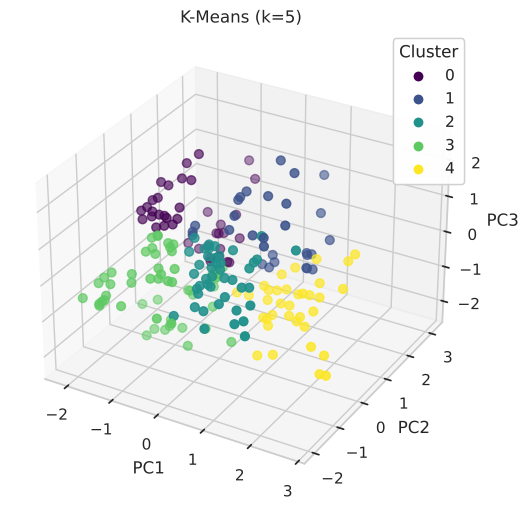

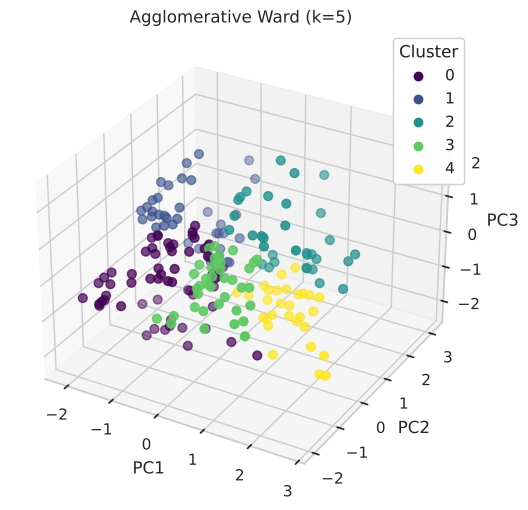

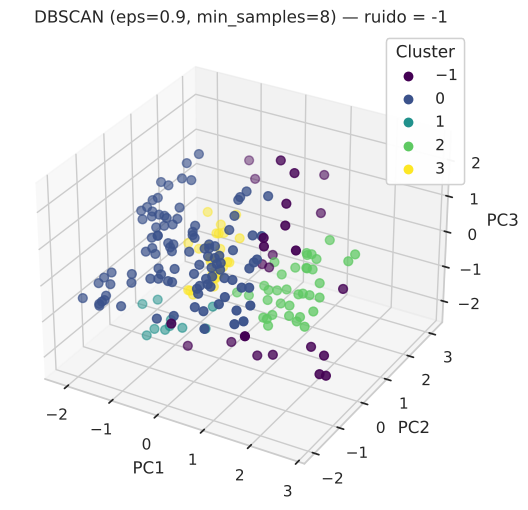

In [19]:
labels_kmeans = labels_km5
labels_agglomerative = labels_ag5

def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels, cmap="viridis", s=40)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title(title)
    legend = ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.add_artist(legend)
    plt.show()

plot_clusters_3d(X_pca, labels_kmeans, "K-Means (k=5)")
plot_clusters_3d(X_pca, labels_agglomerative, "Agglomerative Ward (k=5)")
plot_clusters_3d(X_pca, labels_db, f"DBSCAN (eps={eps_sel}, min_samples={ms_sel}) — ruido = -1")

**Interpretación de los gráficos 3D.**

- **K-Means y Ward** se ven prácticamente iguales, como era de esperar con un 91 % de acuerdo (los colores pueden cambiar porque la numeración de cada método es arbitraria).
- En K-Means, a lo largo de **PC1** (edad vs. gasto), los clusters 0 y 3 (los más jóvenes y que más gastan) quedan del lado negativo, y los clusters 1, 2 y 4 del lado positivo; el cluster 4 (hombres mayores) es el más extremo.
- Los clusters 2 y 4, que tienen un perfil de compra casi igual, se separan sobre todo en **PC2 y PC3**, los ejes donde pesa el género. Esto confirma visualmente que su diferencia es principalmente de género.
- Los clusters 0 y 1 (ingreso alto) se distinguen entre sí por PC1, porque uno gasta mucho y el otro poco.
- **DBSCAN:** los puntos de ruido (`-1`) toman el color más oscuro de la paleta y se mezclan visualmente con los bordes de los clusters, lo que dificulta la lectura. Además, el resultado es desbalanceado: un solo cluster concentra 103 clientes (todas mujeres) y los otros tres son pequeños (10, 36 y 26).

## Fase 5 — Comparación final

In [20]:
sil_km5 = silhouette_score(X_scaled, labels_km5)
sil_ag5 = silhouette_score(X_scaled, labels_ag5)

comparacion = pd.DataFrame([
    ["K-Means", "k = 5", 5, "N/A", round(sil_km5, 4)],
    ["Agglomerative", 'k = 5, linkage="ward"', 5, "N/A", round(sil_ag5, 4)],
    ["DBSCAN", f"eps = {eps_sel}, min_samples = {ms_sel}", n_cl_db, n_noise_db, round(sil_db, 4)],
], columns=["Método", "Parámetros", "N° de clusters", "N° de puntos de ruido", "Silhouette Score"])
comparacion

,Método,Parámetros,N° de clusters,N° de puntos de ruido,Silhouette Score
0,K-Means,k = 5,5,N/A,0.3041
1,Agglomerative,"k = 5, linkage=""ward""",5,N/A,0.2870
2,DBSCAN,"eps = 0.9, min_samples = 8",4,25,0.2685


In [21]:
# Silhouette medio de cada cluster de K-Means (k = 5)
from sklearn.metrics import silhouette_samples

sil_por_cluster = pd.Series(silhouette_samples(X_scaled, labels_km5)).groupby(labels_km5).mean().round(3)
sil_por_cluster.rename_axis("Cluster").rename("Silhouette medio").to_frame()

,Silhouette medio
Cluster,
0,0.367
1,0.190
2,0.406
3,0.205
4,0.356


**Interpretación de la comparación.**

- Entre las configuraciones finales, **K-Means tiene el mayor Silhouette** (0.304), seguido de Ward (0.287) y DBSCAN (0.269). Las diferencias son pequeñas.
- El valor de DBSCAN se calcula **sin** los 25 puntos de ruido, así que no es del todo comparable con los otros dos, que sí evalúan a los 200 clientes.
- Solo K-Means y Ward asignan un segmento a todos los clientes.
- **Silhouette por cluster:** los clusters 2 (0.41), 0 (0.37) y 4 (0.36) son los más cohesionados; los clusters 1 (0.19) y 3 (0.21), los menos. Los clusters 2 y 4 salen tan altos en parte porque son de un solo género (la distancia de 2 unidades los separa mucho de sus vecinos). El cluster 1 es el más difuso, y es justamente donde el clasificador comete sus errores en la Fase 10.

## Fase 6 — ¿Cuáles son las clases naturales?

**Respuesta: 5 grupos, definidos con K-Means (k = 5).**

- **Silhouette:** entre las tres configuraciones finales, K-Means tiene el mayor (0.304). Hay valores más altos en lo explorado (≈ 0.43 con k = 10–17, hasta 0.77 en DBSCAN), pero se deben a partir los grupos por género o a dejar sin asignar a la mayoría de los clientes.
- **Forma y cobertura:** K-Means asigna a todos los clientes en grupos de tamaño útil (29 a 54). DBSCAN deja el 12.5 % como ruido (incluido buena parte del segmento de alto ingreso y bajo gasto) y, por el efecto del género, no puede formar grupos mixtos.
- **Consistencia:** K-Means y Ward coinciden en el 91 % de los clientes (ARI = 0.79), así que la estructura no depende del algoritmo.
- **Interpretabilidad:** k = 5 es el primer k donde aparecen los grupos de alto ingreso; con k = 4 el ingreso no participa, y desde k = 6 los grupos nuevos salen de partir por género.
- **Limitación que reconocemos:** los clusters 2 y 4 tienen un perfil de compra casi igual (adultos mayores de ingreso y gasto medios) y se diferencian sobre todo por género. En términos de negocio son **un mismo segmento dividido por la variable `Gender_encoded`**. Los mantenemos separados porque el enunciado pide usar las 4 variables, pero lo tenemos en cuenta al interpretarlos.

A partir de aquí se usa K-Means con k = 5.

## Fase 7 — Perfilado de los clusters

In [22]:
df["Cluster"] = labels_km5
num = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

print("Tamaño de cada cluster:"); print(df["Cluster"].value_counts().sort_index())
print("\nMEDIA"); display(df.groupby("Cluster")[num].mean().round(1))
print("MEDIANA"); display(df.groupby("Cluster")[num].median())
print("GÉNERO (proporción)"); display(df.groupby("Cluster")["Gender"].value_counts(normalize=True).unstack().fillna(0).round(2))

Tamaño de cada cluster:
Cluster
0    39
1    29
2    43
3    54
4    35
Name: count, dtype: int64

MEDIA


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,32.7,86.5,82.1
1,36.5,89.5,18.0
2,49.8,49.2,40.1
3,24.9,39.7,61.2
4,55.7,53.7,36.8


MEDIANA


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,32.0,79.0,83.0
1,37.0,86.0,17.0
2,49.0,50.0,43.0
3,23.5,39.5,58.0
4,57.0,54.0,43.0


GÉNERO (proporción)


Gender,Female,Male
Cluster,,
0,0.54,0.46
1,0.55,0.45
2,1.00,0.00
3,0.59,0.41
4,0.00,1.00


**Interpretación de las tablas.**

- **Tamaños:** entre 29 y 54 clientes; ningún grupo es marginal.
- **Media vs. mediana:** son parecidas en casi todos los casos. Las excepciones son el ingreso del cluster 0 (media 86.5 vs. mediana 79), estirado por unos pocos clientes de ingreso muy alto (hasta 137 k$), y el gasto del cluster 4 (media 36.8 vs. mediana 43), bajado por algunos clientes con gasto muy bajo.
- **Qué separa a los grupos:** primero el ingreso (clusters 0 y 1 con ≈ 87–90 k$, frente a 40–54 k$ en el resto); dentro de los de ingreso alto, el gasto (82 vs. 18); y entre los de ingreso medio o bajo, la edad (≈ 25 años en el cluster 3 frente a ≈ 50–56 en los clusters 2 y 4).
- **Género:** los clusters 0, 1 y 3 son mixtos, con proporciones parecidas al total (54–59 % de mujeres vs. 56 % en todo el dataset). Los clusters 2 y 4 son de un solo género y tienen valores muy parecidos entre sí (edad 50 vs. 56, ingreso 49 vs. 54, mediana de gasto 43 en ambos).

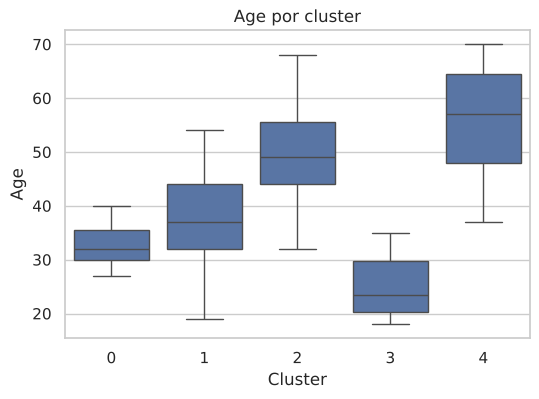

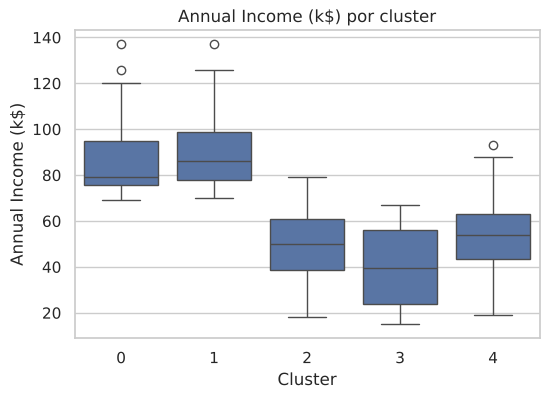

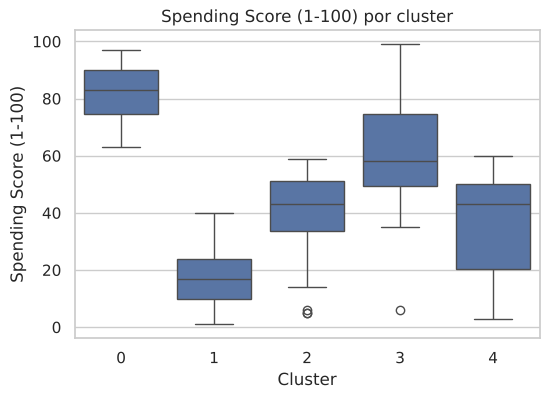

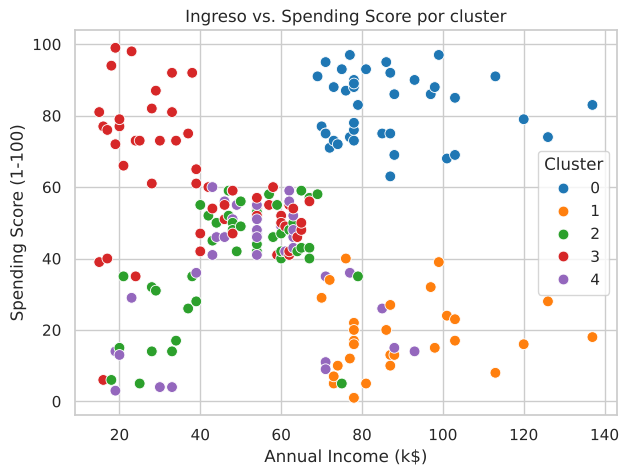

In [23]:
for col in num:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Cluster", y=col)
    plt.title(f"{col} por cluster"); plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Cluster", palette="tab10", s=60)
plt.title("Ingreso vs. Spending Score por cluster"); plt.show()

**Interpretación de los boxplots y del diagrama de dispersión.**

- **Edad:** los clusters 0 (27–40 años) y 3 (18–35) son jóvenes y con poca dispersión; los clusters 2 (32–68) y 4 (37–70) son mayores y muy dispersos; el cluster 1 (19–54) queda en medio.
- **Ingreso:** los clusters 0 y 1 empiezan en 69–70 k$ y sus cajas no se solapan con las del resto. Los clusters 2, 3 y 4 se solapan bastante (entre 15 y 93 k$).
- **Spending Score:** el cluster 0 es alto y concentrado (63–97) y el 1 bajo y concentrado (1–40): son los dos grupos más nítidos. El cluster 3 es alto pero muy disperso (6–99, aunque el 75 % está por encima de 49). Las cajas de los clusters 2 y 4 se solapan casi por completo.
- **Ingreso vs. gasto:** la parte derecha del gráfico (ingreso > 70 k$) está limpia, con el cluster 0 arriba y el cluster 1 abajo. La parte izquierda y central se ve mezclada porque ahí los clusters 2, 3 y 4 se separan por edad y género, variables que este gráfico no muestra.

In [24]:
# ¿Dónde quedaron los clientes de ingreso bajo y gasto bajo (esquina inferior izquierda del diagrama)?
bajo_bajo = df[(df["Annual Income (k$)"] < 40) & (df["Spending Score (1-100)"] < 40)]
print(f"{len(bajo_bajo)} clientes con ingreso < 40 k$ y Spending Score < 40")
bajo_bajo["Cluster"].value_counts().sort_index().rename("Clientes").to_frame()

22 clientes con ingreso < 40 k$ y Spending Score < 40


,Clientes
Cluster,
2,12
3,3
4,7


**Interpretación.** Los 22 clientes de ingreso bajo y gasto bajo no forman un grupo propio: 19 quedan en los clusters 2 y 4 (adultos mayores) y 3 en el cluster 3. Al incluir la edad y el género en el clustering, estas variables pesan más que el ingreso para estos clientes, y el segmento "ingreso bajo, gasto bajo" que suele aparecer cuando se agrupa solo por ingreso y gasto queda repartido entre los grupos de mayor edad.

### Perfil de cada cluster (salido de los números)

| Cluster | n | Edad prom. | Ingreso prom. (k$) | Spending Score prom. | Género | Interpretación / "persona" |
|---:|---:|---:|---:|---:|---|---|
| 0 | 39 | 32.7 | 86.5 | 82.1 | mixto (54 % mujeres) | **Alto ingreso y alto gasto.** Adultos jóvenes con gran poder adquisitivo que además lo usan: el segmento más rentable. |
| 1 | 29 | 36.5 | 89.5 | 18.0 | mixto (55 % mujeres) | **Alto ingreso y bajo gasto.** Tienen dinero pero no lo gastan en el centro comercial: potencial sin aprovechar. Es el grupo menos cohesionado (Silhouette 0.19). |
| 2 | 43 | 49.8 | 49.2 | 40.1 | 100 % mujeres | **Adultas de mediana edad y mayores, con ingreso y gasto medios.** Mismo perfil de compra que el cluster 4. |
| 3 | 54 | 24.9 | 39.7 | 61.2 | mixto (59 % mujeres) | **Jóvenes de ingreso bajo-medio y gasto medio-alto.** El grupo más grande; gastan por encima de lo que su ingreso sugiere, aunque es el grupo más disperso en gasto. |
| 4 | 35 | 55.7 | 53.7 | 36.8 | 100 % hombres | **Adultos de mediana edad y mayores, con ingreso y gasto medios.** Mismo perfil de compra que el cluster 2. |

> Nota: los números de cluster dependen de `random_state=42`; con otra semilla los índices pueden permutarse, pero los perfiles son los mismos.

**¿Qué cluster llama la atención?** El **cluster 1** (ingreso ≈ 90 k$ pero Spending Score ≈ 18): tiene mucho poder adquisitivo desaprovechado. Estrategia: investigar primero por qué no compran (encuestas, oferta de marcas) y luego activar su gasto con propuestas de exclusividad (marcas premium, preventas, experiencias y eventos personalizados). El cluster 3 (jóvenes con ingreso bajo y gasto medio-alto) también sorprende: conviene cuidarlo con promociones, cuotas y cupones, ya que gastan más de lo que su ingreso sugiere. Por último, los clusters 2 y 4 muestran que el género, por sí solo, no genera segmentos de compra distintos.

## Fases 8–10 — El cluster como variable objetivo

Accuracy: 0.95
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      0.67      0.80         6
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00        11
           4       0.78      1.00      0.88         7

    accuracy                           0.95        40
   macro avg       0.96      0.93      0.93        40
weighted avg       0.96      0.95      0.95        40

[[ 8  0  0  0  0]
 [ 0  4  0  0  2]
 [ 0  0  8  0  0]
 [ 0  0  0 11  0]
 [ 0  0  0  0  7]]


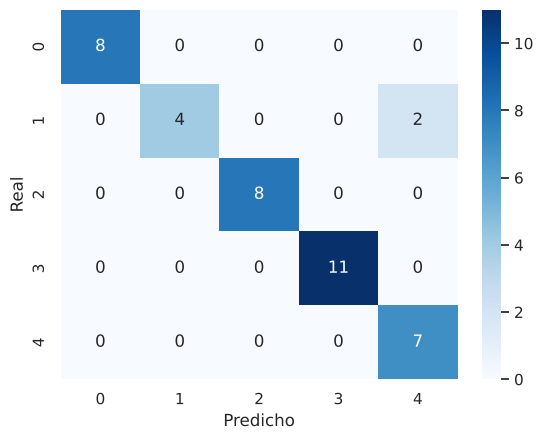

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

X = df[["Gender_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]]
y = df["Cluster"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=5)),
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues"); plt.xlabel("Predicho"); plt.ylabel("Real"); plt.show()

**Interpretación del reporte y de la matriz de confusión.**

- **Accuracy 0.95:** 38 de los 40 clientes del test se asignan a su cluster correcto.
- Los clusters 0, 2 y 3 tienen precisión y recall de 1.00.
- **Cluster 1:** precisión 1.00 (todo lo que el modelo predice como cluster 1 es correcto) pero recall 0.67 (se le escapan 2 de sus 6 clientes).
- **Cluster 4:** recall 1.00 pero precisión 0.78 (de los 9 clientes que predice como cluster 4, 2 eran en realidad del cluster 1).
- **Matriz de confusión:** la diagonal concentra casi todo; los únicos errores están en la celda *real 1 → predicho 4*.
- El *macro avg* de F1 (0.93) es algo menor que la accuracy (0.95) porque los errores se concentran en una clase pequeña (6 clientes), y el promedio macro le da a cada clase el mismo peso.

In [26]:
# Los clientes mal clasificados, comparados con el perfil medio de los clusters 1 y 4
mal = y_test.values != y_pred
errores = X_test[mal].assign(Real=y_test.values[mal], Predicho=y_pred[mal])
display(errores)
df.groupby("Cluster")[features].mean().loc[[1, 4]].round(1)

,Gender_encoded,Age,Annual Income (k$),Spending Score (1-100),Real,Predicho
150,0,43,78,17,1,4
182,0,46,98,15,1,4


,Gender_encoded,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
1,0.6,36.5,89.5,18.0
4,0.0,55.7,53.7,36.8


**Interpretación de los errores.** Los 2 errores son **hombres de 43 y 46 años**, con ingreso alto (78 y 98 k$) y gasto bajo (17 y 15). Por ingreso y gasto encajan bien en el cluster 1, pero son mayores que su promedio (36.5 años) y son hombres, mientras que el cluster 1 es 55 % mujeres. El cluster 4, en cambio, es 100 % hombres, con edades de 37 a 70 años, e incluye clientes con ingreso de hasta 93 k$ y gasto bajo. En la escala estandarizada, coincidir en género (que pesa ≈ 2 unidades) y acercarse en edad basta para que la mayoría de sus 5 vecinos más cercanos sean del cluster 4.

**Sobre `stratify=y`:** mantiene la proporción de cada cluster en train y test. Con solo 200 clientes y clusters de 29 a 54 miembros, un split aleatorio podría dejar casi sin representación a algún cluster en el test.

**Clasificador elegido:** KNN (k = 5) dentro de un `Pipeline` con `StandardScaler`, porque es un modelo basado en distancias, igual que el clustering.

**Preguntas de cierre**

1. **¿Qué tan bien predijo el cluster?** Muy bien: accuracy de 0.95 (38 de 40 clientes del test). Los clusters 0, 2 y 3 se predicen sin errores; el único punto débil es el cluster 1, con recall de 0.67 (4 de 6 bien clasificados).
2. **Accuracy alto, ¿qué dice de los clusters?** Que son muy separables en el espacio de características: un KNN simple reconstruye la asignación sin re-ejecutar el clustering, así que sirve para asignar segmento a un cliente nuevo. Ojo con la interpretación: las etiquetas salieron de esas mismas variables, así que un accuracy alto era esperable (no es una validación independiente de que los segmentos "existan" en la realidad), y con solo 40 clientes en el test cada error pesa 2.5 puntos.
3. **¿Dónde se equivocó?** Los 2 errores fueron clientes del cluster 1 (alto ingreso, bajo gasto) predichos como cluster 4 (hombres, perfil medio). Los perfiles promedio son distintos (ingreso ≈ 90 vs. ≈ 54), pero los dos clientes son hombres de 43 y 46 años, más cercanos en género y edad al cluster 4 que el cliente típico del cluster 1. Tiene sentido que el modelo los confunda: son puntos de frontera, y el cluster 1 es el menos cohesionado (Silhouette 0.19). Con solo 6 clientes de ese cluster en el test, la métrica es poco estable.

## Reflexión final

**¿El método con mayor Silhouette fue el que usamos para definir los segmentos?** Entre las tres configuraciones finales, **sí**: K-Means con k = 5 tiene el mayor Silhouette (0.304). Pero **no** es el máximo de todo lo explorado: K-Means con k = 14 llega a 0.432 y DBSCAN con `eps = 0.5` hasta 0.77. No elegimos K-Means por el score, sino porque entrega grupos interpretables que asignan a todos los clientes, coincide con el jerárquico en el 91 % de los casos y evita los valores de k donde el Silhouette sube solo por partir los grupos por género. El Silhouette es una guía, no el criterio único.

**Recomendación de marketing por segmento (una frase cada uno):**

- **Cluster 0 (alto ingreso, alto gasto):** programa VIP de fidelización con acceso anticipado y beneficios exclusivos para retenerlos.
- **Cluster 1 (alto ingreso, bajo gasto):** investigar por qué no compran y activarlos con marcas premium, preventas y experiencias personalizadas.
- **Cluster 3 (jóvenes, ingreso bajo-medio, gasto medio-alto):** cupones, cuotas sin interés y promociones frecuentes que cuiden su gasto sin exceder su capacidad de pago.
- **Clusters 2 y 4 (adultos mayores de ingreso y gasto medios):** tratarlos como un mismo segmento, con beneficios por recurrencia (puntos, combos) para subir el ticket promedio; los datos no muestran diferencias de compra entre mujeres y hombres que justifiquen campañas distintas.